# Reliability Analysis of an INT8-Quantized ResNet-18 Under Single-Bit Weight Faults

This project investigates the effect of single-bit faults in the stored INT8 weights of a quantized ResNet-18 trained on CIFAR-10.

The experimental workflow consists of:

- training and evaluating a FP32 ResNet-18 baseline;
- applying static post-training INT8 quantization;
- selecting 1,000 fixed random weight locations across the quantized model;
- injecting one bit flip at each location for all eight INT8 bit positions;
- evaluating the faulty model after each injection; and
- analysing fault sensitivity with respect to bit position, network layer, and ResNet stage.

The same 1,000 physical weight locations are used for all eight bit positions, resulting in a total of 8,000 fault injections.

In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("PyTorch CUDA:", torch.version.cuda)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.0+cu132
CUDA available: True
PyTorch CUDA: 13.2
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## Reproducibility

A fixed random seed is used throughout the notebook to make the experimental setup reproducible. The seed is applied to Python, NumPy, and PyTorch, including CUDA when available.

In [2]:
import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Seed set to:", SEED)

Seed set to: 42


In [3]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)

Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
CUDA version: 13.2


## Dataset and preprocessing

The experiments use the CIFAR-10 dataset, consisting of 50,000 training images and 10,000 test images across 10 classes.

For training, random cropping and horizontal flipping are applied as data augmentation. Both training and test images are then converted to tensors and normalized using CIFAR-10 channel statistics.

The test set uses deterministic preprocessing without data augmentation, since it is used for baseline evaluation and later fault-injection measurements.

In [4]:
from torchvision import datasets, transforms

# CIFAR-10 normalization values
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD = (0.2470, 0.2435, 0.2616)

# Training data augmentation + normalization
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD)
])

# Test data: no augmentation, only normalization
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD)
])

# Download/load training set
train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=train_transform
)

# Download/load test set
test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=test_transform
)

print("Training samples:", len(train_dataset))
print("Test samples:", len(test_dataset))
print("Classes:", train_dataset.classes)

Training samples: 50000
Test samples: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [5]:
from torch.utils.data import DataLoader

BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Test batches:", len(test_loader))

Train batches: 391
Test batches: 79


## ResNet-18 model

A ResNet-18 architecture is used as the baseline classifier.

Since CIFAR-10 images are only 32×32 pixels, the standard ImageNet ResNet-18 input stem is modified:

- the initial 7×7 convolution is replaced with a 3×3 convolution;
- the stride is reduced from 2 to 1;
- the initial max-pooling layer is removed;
- the final fully connected layer is replaced with a 10-class output layer.

These changes preserve the ResNet-18 residual architecture while adapting it to the lower spatial resolution of CIFAR-10.

In [6]:
import torch.nn as nn
from torchvision import models

model = models.resnet18(weights=None)

# Adapt the first convolution for 32x32 CIFAR-10 images
model.conv1 = nn.Conv2d(
    in_channels=3,
    out_channels=64,
    kernel_size=3,
    stride=1,
    padding=1,
    bias=False
)

# Remove the initial max-pooling layer
model.maxpool = nn.Identity()

# CIFAR-10 has 10 classes
model.fc = nn.Linear(
    model.fc.in_features,
    10
)

model = model.to(device)

total_params = sum(p.numel() for p in model.parameters())

print(model.__class__.__name__)
print(f"Total parameters: {total_params:,}")

ResNet
Total parameters: 11,173,962


In [7]:
images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

model.eval()

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Labels shape:", labels.shape)

Input shape: torch.Size([128, 3, 32, 32])
Output shape: torch.Size([128, 10])
Labels shape: torch.Size([128])


## Training configuration

The model is trained using cross-entropy loss and stochastic gradient descent (SGD) with momentum.

The initial learning rate is set to 0.1, with momentum 0.9 and weight decay $5\times10^{-4}$. A multi-step learning-rate scheduler reduces the learning rate by a factor of 10 after epochs 50 and 75.

This configuration is used for the full ResNet-18 training run before quantization.

In [8]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(
    model.parameters(),
    lr=0.1,
    momentum=0.9,
    weight_decay=5e-4
)

scheduler = optim.lr_scheduler.MultiStepLR(
    optimizer,
    milestones=[50, 75],
    gamma=0.1
)

print("Loss:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Initial learning rate:", optimizer.param_groups[0]["lr"])

Loss: CrossEntropyLoss()
Optimizer: SGD
Initial learning rate: 0.1


In [9]:
@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        total_loss += loss.item() * images.size(0)

        _, predicted = outputs.max(1)

        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    average_loss = total_loss / total
    accuracy = 100.0 * correct / total

    return average_loss, accuracy

### Final model initialization

Before the full training run, the ResNet-18 model, optimizer, and learning-rate scheduler are initialized again to ensure that training starts from a fresh model state.

In [10]:
# Re-create a fresh ResNet-18
model = models.resnet18(weights=None)

model.conv1 = nn.Conv2d(
    in_channels=3,
    out_channels=64,
    kernel_size=3,
    stride=1,
    padding=1,
    bias=False
)

model.maxpool = nn.Identity()

model.fc = nn.Linear(
    model.fc.in_features,
    10
)

model = model.to(device)

# Re-create optimizer and scheduler
criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(
    model.parameters(),
    lr=0.1,
    momentum=0.9,
    weight_decay=5e-4
)

scheduler = optim.lr_scheduler.MultiStepLR(
    optimizer,
    milestones=[50, 75],
    gamma=0.1
)

print("model initialized.")
print("Device:", next(model.parameters()).device)
print("Initial LR:", optimizer.param_groups[0]["lr"])

model initialized.
Device: cuda:0
Initial LR: 0.1


### Full FP32 training

The ResNet-18 model is trained for 100 epochs. After each epoch, training loss, training accuracy, test loss, and test accuracy are recorded.

The learning-rate scheduler reduces the learning rate from 0.1 to 0.01 after epoch 50 and to 0.001 after epoch 75. Whenever a new best test accuracy is obtained, the corresponding model weights are saved to `resnet18_cifar10_fp32_best.pth`.

The best test accuracy obtained during training is **94.35%**.

In [12]:
EPOCHS = 100
best_accuracy = 0.0

for epoch in range(EPOCHS):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = outputs.max(1)

        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    train_loss = running_loss / total
    train_accuracy = 100.0 * correct / total

    test_loss, test_accuracy = evaluate(
        model,
        test_loader,
        device
    )

    scheduler.step()

    if test_accuracy > best_accuracy:
        best_accuracy = test_accuracy

        torch.save(
            model.state_dict(),
            "resnet18_cifar10_fp32_best.pth"
        )

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch [{epoch+1:3d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {test_accuracy:.2f}% | "
        f"Best: {best_accuracy:.2f}% | "
        f"LR: {current_lr:.5f}"
    )

Epoch [  1/100] | Train Loss: 2.1184 | Train Acc: 27.31% | Test Loss: 1.6855 | Test Acc: 37.66% | Best: 37.66% | LR: 0.10000
Epoch [  2/100] | Train Loss: 1.5695 | Train Acc: 42.45% | Test Loss: 1.4075 | Test Acc: 47.52% | Best: 47.52% | LR: 0.10000
Epoch [  3/100] | Train Loss: 1.3611 | Train Acc: 50.52% | Test Loss: 1.3378 | Test Acc: 53.04% | Best: 53.04% | LR: 0.10000
Epoch [  4/100] | Train Loss: 1.1374 | Train Acc: 59.31% | Test Loss: 1.2156 | Test Acc: 58.19% | Best: 58.19% | LR: 0.10000
Epoch [  5/100] | Train Loss: 0.9422 | Train Acc: 66.40% | Test Loss: 0.9058 | Test Acc: 68.01% | Best: 68.01% | LR: 0.10000
Epoch [  6/100] | Train Loss: 0.7838 | Train Acc: 72.29% | Test Loss: 1.0808 | Test Acc: 64.24% | Best: 68.01% | LR: 0.10000
Epoch [  7/100] | Train Loss: 0.6779 | Train Acc: 76.42% | Test Loss: 0.7694 | Test Acc: 73.05% | Best: 73.05% | LR: 0.10000
Epoch [  8/100] | Train Loss: 0.6114 | Train Acc: 78.98% | Test Loss: 0.8442 | Test Acc: 72.81% | Best: 73.05% | LR: 0.10000


## FP32 baseline evaluation

The best checkpoint obtained during training is reloaded and evaluated on the complete CIFAR-10 test set.

This provides the reference FP32 performance against which the INT8 quantized model is compared.

The resulting baseline performance is:

- **Test loss:** 0.2200
- **Test accuracy:** 94.35%

In [10]:
model.load_state_dict(
    torch.load(
        "resnet18_cifar10_fp32_best.pth",
        map_location=device
    )
)

model = model.to(device)

fp32_test_loss, fp32_test_accuracy = evaluate(
    model,
    test_loader,
    device
)

print("FP32 BASELINE")
print(f"Test Loss:     {fp32_test_loss:.4f}")
print(f"Test Accuracy: {fp32_test_accuracy:.2f}%")

FP32 BASELINE
Test Loss:     0.2200
Test Accuracy: 94.35%


## INT8 quantization

PyTorch quantized operators are executed on the CPU, so a separate copy of the trained FP32 model is created and moved to the CPU.

The original trained FP32 model is kept unchanged, while `fp32_model_cpu` is used for the quantization workflow.

In [11]:
import copy
import torch

# Quantized PyTorch models run on CPU
cpu_device = torch.device("cpu")

# Make a separate copy so the trained FP32 model remains untouched
fp32_model_cpu = copy.deepcopy(model).to(cpu_device)

fp32_model_cpu.eval()

print("FP32 model copied to CPU.")
print("Model device:", next(fp32_model_cpu.parameters()).device)

FP32 model copied to CPU.
Model device: cpu


In [12]:
print("Supported quantization engines:",
      torch.backends.quantized.supported_engines)

print("Current engine:",
      torch.backends.quantized.engine)

Supported quantization engines: ['onednn']
Current engine: onednn


### Calibration dataset

Static post-training quantization requires representative input data to estimate activation ranges.

A deterministic subset of **5,000 CIFAR-10 training images** is therefore selected using the fixed random seed. The calibration data use the same normalization as the test set and no random data augmentation.

The subset is divided into 40 batches of 128 images and is used only for quantization calibration.

In [13]:
from torch.utils.data import DataLoader, Subset
from torchvision import datasets
import torch

CALIBRATION_SAMPLES = 5000

# Same normalization as the test set, but no random augmentation
calibration_dataset_full = datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=test_transform
)

# Reproducible random subset of the training set
generator = torch.Generator().manual_seed(SEED)

calibration_indices = torch.randperm(
    len(calibration_dataset_full),
    generator=generator
)[:CALIBRATION_SAMPLES]

calibration_dataset = Subset(
    calibration_dataset_full,
    calibration_indices
)

calibration_loader = DataLoader(
    calibration_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0
)

print("Calibration samples:", len(calibration_dataset))
print("Calibration batches:", len(calibration_loader))

Calibration samples: 5000
Calibration batches: 40


### FX graph preparation for static quantization

Static INT8 quantization is configured using the oneDNN backend.

A separate copy of the trained FP32 model is prepared with PyTorch FX graph-mode quantization. The default oneDNN quantization configuration is applied, and a sample input with shape 1×3×32×32 is used to trace and prepare the graph.

At this stage, observers are inserted into the model so that activation ranges can be collected during calibration.

In [14]:
from torch.ao.quantization import get_default_qconfig_mapping
from torch.ao.quantization.quantize_fx import prepare_fx, convert_fx
import copy
import torch

backend = "onednn"

print("Quantization backend:", backend)

# Independent copy of the trained FP32 model
model_to_quantize = copy.deepcopy(fp32_model_cpu)
model_to_quantize.eval()

# Static INT8 quantization configuration
qconfig_mapping = get_default_qconfig_mapping(backend)

# Example input for FX graph preparation
example_inputs = (
    torch.randn(1, 3, 32, 32),
)

prepared_model = prepare_fx(
    model_to_quantize,
    qconfig_mapping,
    example_inputs
)

prepared_model.eval()

print("Model prepared for INT8 calibration.")

Quantization backend: onednn


Model prepared for INT8 calibration.


In [15]:
prepared_model.eval()

print("Starting calibration...")

with torch.no_grad():
    for images, _ in calibration_loader:
        prepared_model(images)

print("Calibration completed.")

Starting calibration...
Calibration completed.


In [50]:
int8_model = convert_fx(prepared_model)

int8_model.eval()

print("INT8 model created.")

INT8 model created.


### INT8 baseline evaluation

The quantized model is evaluated on the complete CIFAR-10 test set before any fault is injected.

The INT8 model achieves **94.26%** test accuracy, compared with **94.35%** for the FP32 model. The quantization therefore introduces an accuracy reduction of only **0.09 percentage points**.

This fault-free INT8 model serves as the reference for the subsequent fault-injection experiments.

In [17]:
int8_test_loss, int8_test_accuracy = evaluate(
    int8_model,
    test_loader,
    torch.device("cpu")
)

print("INT8 FAULT-FREE BASELINE")
print(f"Test Loss:     {int8_test_loss:.4f}")
print(f"Test Accuracy: {int8_test_accuracy:.2f}%")

print()
print(f"FP32 Accuracy: {fp32_test_accuracy:.2f}%")
print(f"INT8 Accuracy: {int8_test_accuracy:.2f}%")
print(
    f"Accuracy Drop: "
    f"{fp32_test_accuracy - int8_test_accuracy:.2f} percentage points"
)

INT8 FAULT-FREE BASELINE
Test Loss:     0.2209
Test Accuracy: 94.26%

FP32 Accuracy: 94.35%
INT8 Accuracy: 94.26%
Accuracy Drop: 0.09 percentage points


## Quantized weight inventory

Before defining the fault model, the quantized weight tensors are identified explicitly.

For each quantized layer, the notebook records the layer name, module type, tensor shape, INT8 datatype, quantization scheme, and number of stored weights.

The quantized ResNet-18 contains:

- **21 quantized weight layers**
- **11,164,352 quantized weights in total**

These tensors define the population from which fault-injection locations are later sampled.

In [18]:
quantized_layers = []

for name, module in int8_model.named_modules():
    if hasattr(module, "weight") and callable(module.weight):
        try:
            weight = module.weight()

            if isinstance(weight, torch.Tensor) and weight.is_quantized:
                quantized_layers.append((name, module, weight))

                print(f"Layer: {name}")
                print(f"  Module: {module.__class__.__name__}")
                print(f"  Shape: {tuple(weight.shape)}")
                print(f"  Dtype: {weight.dtype}")
                print(f"  QScheme: {weight.qscheme()}")
                print(f"  Number of weights: {weight.numel():,}")
                print()

        except Exception:
            pass

print("Number of quantized weight layers:", len(quantized_layers))

total_quantized_weights = sum(
    weight.numel()
    for _, _, weight in quantized_layers
)

print(f"Total quantized weights: {total_quantized_weights:,}")

Layer: conv1
  Module: ConvReLU2d
  Shape: (64, 3, 3, 3)
  Dtype: torch.qint8
  QScheme: torch.per_channel_affine
  Number of weights: 1,728

Layer: layer1.0.conv1
  Module: ConvReLU2d
  Shape: (64, 64, 3, 3)
  Dtype: torch.qint8
  QScheme: torch.per_channel_affine
  Number of weights: 36,864

Layer: layer1.0.conv2
  Module: Conv2d
  Shape: (64, 64, 3, 3)
  Dtype: torch.qint8
  QScheme: torch.per_channel_affine
  Number of weights: 36,864

Layer: layer1.1.conv1
  Module: ConvReLU2d
  Shape: (64, 64, 3, 3)
  Dtype: torch.qint8
  QScheme: torch.per_channel_affine
  Number of weights: 36,864

Layer: layer1.1.conv2
  Module: Conv2d
  Shape: (64, 64, 3, 3)
  Dtype: torch.qint8
  QScheme: torch.per_channel_affine
  Number of weights: 36,864

Layer: layer2.0.conv1
  Module: ConvReLU2d
  Shape: (128, 64, 3, 3)
  Dtype: torch.qint8
  QScheme: torch.per_channel_affine
  Number of weights: 73,728

Layer: layer2.0.conv2
  Module: Conv2d
  Shape: (128, 128, 3, 3)
  Dtype: torch.qint8
  QScheme: tor

## INT8 weight representation

Fault injection is performed on the underlying stored integer representation of each quantized weight rather than on its dequantized floating-point value.

The first quantized layer is inspected to verify this representation. Its weights are stored as signed `torch.int8` values using per-channel affine quantization.

The `int_repr()` method provides direct access to these stored 8-bit integer values, which are the values modified during the fault-injection experiments.

In [19]:
layer_name, layer_module, weight = quantized_layers[0]

raw_weights = weight.int_repr()

print("Layer:", layer_name)
print("Quantized dtype:", weight.dtype)
print("Raw integer dtype:", raw_weights.dtype)
print("Quantization scheme:", weight.qscheme())

print()
print("First 10 raw INT8 values:")
print(raw_weights.flatten()[:10])

print()
print("First raw stored value:")
print(raw_weights.flatten()[0].item())

print("First dequantized value:")
print(weight.dequantize().flatten()[0].item())

print()
print("Quantization axis:", weight.q_per_channel_axis())
print("First 5 scales:")
print(weight.q_per_channel_scales()[:5])

print("First 5 zero points:")
print(weight.q_per_channel_zero_points()[:5])

Layer: conv1
Quantized dtype: torch.qint8
Raw integer dtype: torch.int8
Quantization scheme: torch.per_channel_affine

First 10 raw INT8 values:
tensor([ -19, -115, -100,  -13, -128,  -83,  -27, -102,  -70,   11],
       dtype=torch.int8)

First raw stored value:
-19
First dequantized value:
-2.7295063773635775e-05

Quantization axis: 0
First 5 scales:
tensor([1.4366e-06, 2.1424e-04, 4.2130e-04, 1.1921e-07, 7.2669e-04],
       dtype=torch.float64)
First 5 zero points:
tensor([0, 0, 0, 0, 0])


## Single-bit fault model

Each injected fault is modeled as a single-bit inversion in one signed INT8 weight.

Bit positions are indexed as:

- **Bit 0:** least significant bit (LSB)
- **Bit 7:** most significant bit (MSB)

The helper function below first interprets the signed INT8 value as its 8-bit unsigned representation, flips the selected bit using XOR, and then converts the result back to the corresponding signed INT8 value.

This ensures that each fault changes exactly one stored bit while preserving the standard two's-complement INT8 representation.

In [ ]:
def flip_int8_bit(value, bit_position):
    """
    Flip one bit of a signed INT8 value.

    bit_position:
        0 = LSB
        7 = MSB
    """

    if bit_position < 0 or bit_position > 7:
        raise ValueError("bit_position must be between 0 and 7")

    # Convert signed INT8 value to its unsigned 8-bit representation
    unsigned_value = value & 0xFF

    # Flip the selected bit
    flipped_unsigned = unsigned_value ^ (1 << bit_position)

    # Convert back to signed INT8
    if flipped_unsigned >= 128:
        flipped_signed = flipped_unsigned - 256
    else:
        flipped_signed = flipped_unsigned

    return flipped_signed

## Fixed fault-evaluation subset

Running a full 10,000-image test-set evaluation after every injected fault would make the complete experiment prohibitively slow.

To reduce the computational cost while keeping the evaluation set balanced and reproducible, a fixed subset of **2,500 CIFAR-10 test images** is used for all fault-injection experiments.

The subset contains exactly **250 images from each of the 10 classes** and is generated using seed 42. The selected indices are saved to disk so that the same evaluation images are reused across every fault injection and every bit position.

Using a fixed subset is important because it ensures that differences between fault injections are caused by the injected faults rather than by changes in the evaluation data.

In [21]:
# ============================================================
# CREATE FIXED BALANCED 2500-IMAGE CIFAR-10 SUBSET
# 250 images per class
# ============================================================

import os
import numpy as np

SUBSET_PER_CLASS = 250
SUBSET_SEED = 42
SUBSET_FILE = "cifar10_fault_eval_indices_2500_seed42.npy"

targets = np.array(test_dataset.targets)

if os.path.exists(SUBSET_FILE):
    subset_indices = np.load(SUBSET_FILE)
    print("Existing evaluation subset loaded.")

else:
    rng = np.random.default_rng(SUBSET_SEED)

    selected_indices = []

    for class_id in range(10):
        class_indices = np.where(targets == class_id)[0]

        chosen = rng.choice(
            class_indices,
            size=SUBSET_PER_CLASS,
            replace=False
        )

        selected_indices.extend(chosen)

    subset_indices = np.array(selected_indices)

    # Deterministic shuffle
    rng.shuffle(subset_indices)

    np.save(SUBSET_FILE, subset_indices)

    print("New evaluation subset created and saved.")

print()
print("Total evaluation images:", len(subset_indices))

selected_targets = targets[subset_indices]

for class_id in range(10):
    count = np.sum(selected_targets == class_id)
    print(f"Class {class_id}: {count}")

Existing evaluation subset loaded.

Total evaluation images: 2500
Class 0: 250
Class 1: 250
Class 2: 250
Class 3: 250
Class 4: 250
Class 5: 250
Class 6: 250
Class 7: 250
Class 8: 250
Class 9: 250


In [22]:
# ============================================================
# PRELOAD THE FIXED 2500-IMAGE SUBSET INTO RAM
# ============================================================

import torch

eval_images = []
eval_labels = []

for idx in subset_indices:
    image, label = test_dataset[int(idx)]

    eval_images.append(image)
    eval_labels.append(label)

eval_images = torch.stack(eval_images).contiguous()

eval_labels = torch.tensor(
    eval_labels,
    dtype=torch.long
)

print("Images tensor:", eval_images.shape)
print("Labels tensor:", eval_labels.shape)
print("Subset successfully loaded into RAM.")

Images tensor: torch.Size([2500, 3, 32, 32])
Labels tensor: torch.Size([2500])
Subset successfully loaded into RAM.


In [23]:
# ============================================================
# FAST EVALUATION FUNCTION FOR THE FIXED 2500-IMAGE SUBSET
# ============================================================

@torch.inference_mode()
def evaluate_accuracy_fast(
    model,
    images,
    labels,
    batch_size=1024
):
    model.eval()

    correct = 0
    total = 0

    for start in range(0, len(labels), batch_size):
        end = min(start + batch_size, len(labels))

        x = images[start:end]
        y = labels[start:end]

        outputs = model(x)
        predicted = outputs.argmax(dim=1)

        correct += (predicted == y).sum().item()
        total += y.numel()

    return 100.0 * correct / total


print("Fast evaluation function created successfully.")

Fast evaluation function created successfully.


### Evaluation subset validation and runtime

The fault-free INT8 model is evaluated on the fixed 2,500-image subset before starting the injection campaigns.

The subset produces **94.80% accuracy**, which is close to the 94.26% accuracy measured on the complete test set.

A single evaluation takes approximately **5.77 seconds**, reducing the estimated runtime for 1,000 fault injections to about **1.60 hours**. This makes the full eight-bit campaign computationally practical.

In [24]:
# ============================================================
# TEST CLEAN INT8 ACCURACY + TIMING ON 2500-IMAGE SUBSET
# ============================================================

import time

start = time.perf_counter()

subset_clean_accuracy = evaluate_accuracy_fast(
    int8_model,
    eval_images,
    eval_labels,
    batch_size=1024
)

elapsed = time.perf_counter() - start

print(f"2500-image subset accuracy: {subset_clean_accuracy:.2f}%")
print(f"Evaluation time: {elapsed:.2f} seconds")
print(f"Estimated time for 1000 injections: {elapsed * 1000 / 3600:.2f} hours")

2500-image subset accuracy: 94.80%
Evaluation time: 5.77 seconds
Estimated time for 1000 injections: 1.60 hours


## Global quantized-weight index space

To sample fault locations uniformly across the complete quantized model, all quantized weight tensors are mapped into a single global index space.

For each quantized layer, the number of stored weights is recorded. Cumulative layer boundaries are then computed so that any global weight index can be mapped back to:

- its corresponding quantized layer; and
- its local index inside that layer.

The resulting global fault space contains **11,164,352 quantized weights** distributed across **21 quantized layers**.

In [25]:
# ============================================================
# BUILD CATALOG OF ALL QUANTIZED WEIGHTS
# ============================================================

import numpy as np

layer_catalog = []

for name, module in int8_model.named_modules():

    if hasattr(module, "weight") and callable(module.weight):

        try:
            qweight = module.weight()
        except Exception:
            continue

        if isinstance(qweight, torch.Tensor) and qweight.is_quantized:

            layer_catalog.append({
                "name": name,
                "module": module,
                "numel": qweight.numel()
            })


# Number of weights in each quantized layer
layer_sizes = np.array(
    [layer["numel"] for layer in layer_catalog],
    dtype=np.int64
)

# Cumulative endpoints used later to map a global weight
# index to its corresponding layer
layer_ends = np.cumsum(layer_sizes)

total_weights = int(layer_ends[-1])


print("Quantized layers:", len(layer_catalog))
print(f"Total quantized weights: {total_weights:,}")

print("\nQuantized layers:")
for i, layer in enumerate(layer_catalog):
    print(
        f"{i:2d} | "
        f"{layer['name']:25s} | "
        f"{layer['numel']:,} weights"
    )

Quantized layers: 21
Total quantized weights: 11,164,352

Quantized layers:
 0 | conv1                     | 1,728 weights
 1 | layer1.0.conv1            | 36,864 weights
 2 | layer1.0.conv2            | 36,864 weights
 3 | layer1.1.conv1            | 36,864 weights
 4 | layer1.1.conv2            | 36,864 weights
 5 | layer2.0.conv1            | 73,728 weights
 6 | layer2.0.conv2            | 147,456 weights
 7 | layer2.0.downsample.0     | 8,192 weights
 8 | layer2.1.conv1            | 147,456 weights
 9 | layer2.1.conv2            | 147,456 weights
10 | layer3.0.conv1            | 294,912 weights
11 | layer3.0.conv2            | 589,824 weights
12 | layer3.0.downsample.0     | 32,768 weights
13 | layer3.1.conv1            | 589,824 weights
14 | layer3.1.conv2            | 589,824 weights
15 | layer4.0.conv1            | 1,179,648 weights
16 | layer4.0.conv2            | 2,359,296 weights
17 | layer4.0.downsample.0     | 131,072 weights
18 | layer4.1.conv1            | 2,359,296 weigh

## Fixed fault-location sampling

A total of **1,000 unique quantized weight locations** are selected uniformly at random from the full set of 11,164,352 quantized weights.

The sampling uses seed 42 and is performed without replacement. The selected locations are saved to `fault_locations_1000_seed42.csv` so that the same physical weight locations can be reused consistently.

For each selected location, the notebook stores:

- injection ID;
- global weight index;
- corresponding layer name; and
- local weight index within that layer.

The same 1,000 locations are later tested for **all eight INT8 bit positions**, which enables paired comparisons across bit positions.

In [26]:
# ============================================================
# CREATE 1000 FIXED RANDOM FAULT LOCATIONS
# SAME LOCATIONS WILL BE USED FOR ALL 8 BITS
# ============================================================

import os
import pandas as pd
import numpy as np

N_INJECTIONS = 1000
LOCATION_SEED = 42
LOCATIONS_FILE = "fault_locations_1000_seed42.csv"

if os.path.exists(LOCATIONS_FILE):

    location_df = pd.read_csv(LOCATIONS_FILE)

    selected_global_indices = (
        location_df["global_weight_index"]
        .to_numpy(dtype=np.int64)
    )

    print("Existing fault-location file loaded.")

else:

    rng = np.random.default_rng(LOCATION_SEED)

    # Uniformly sample 1000 unique weights
    # from all 11,164,352 quantized weights
    selected_global_indices = rng.choice(
        total_weights,
        size=N_INJECTIONS,
        replace=False
    )

    rows = []

    for injection_id, global_idx in enumerate(
        selected_global_indices,
        start=1
    ):

        # Determine which layer contains this global weight index
        layer_idx = int(
            np.searchsorted(
                layer_ends,
                global_idx,
                side="right"
            )
        )

        if layer_idx == 0:
            layer_start = 0
        else:
            layer_start = int(layer_ends[layer_idx - 1])

        local_idx = int(global_idx - layer_start)

        rows.append({
            "injection_id": injection_id,
            "global_weight_index": int(global_idx),
            "layer_name": layer_catalog[layer_idx]["name"],
            "local_weight_index": local_idx
        })

    location_df = pd.DataFrame(rows)

    location_df.to_csv(
        LOCATIONS_FILE,
        index=False
    )

    print("New fault-location file created and saved.")


print()
print("Number of selected fault locations:", len(location_df))
print("Unique global locations:", location_df["global_weight_index"].nunique())

print("\nFirst 10 fault locations:")
print(location_df.head(10))

print("\nNumber of selected faults per layer:")
print(
    location_df["layer_name"]
    .value_counts()
    .sort_index()
)

Existing fault-location file loaded.

Number of selected fault locations: 1000
Unique global locations: 1000

First 10 fault locations:
   injection_id  global_weight_index             layer_name  \
0             1              3365942         layer4.0.conv1   
1             2              5432875         layer4.0.conv2   
2             3              3526943         layer4.0.conv1   
3             4               323755         layer2.0.conv2   
4             5              6333018  layer4.0.downsample.0   
5             6              3310451         layer4.0.conv1   
6             7              2771972         layer4.0.conv1   
7             8              1502134         layer3.0.conv2   
8             9              2155161         layer3.1.conv1   
9            10              1793831         layer3.1.conv1   

   local_weight_index  
0              595318  
1             1482603  
2              756319  
3              100843  
4               23450  
5              539827  
6 

## Rebuilding modified quantized weights

After a raw INT8 value is changed, the corresponding quantized tensor must be reconstructed before it can be written back into the model.

The helper function below preserves the original quantization parameters while replacing only the modified integer representation.

It supports both per-channel and per-tensor quantization schemes and keeps the original scales, zero points, and quantization axis unchanged.

In [27]:
# ============================================================
# HELPER FUNCTION:
# REBUILD A QUANTIZED WEIGHT TENSOR AFTER MODIFYING INT8 VALUES
# ============================================================

def rebuild_quantized_weight(qweight, raw_int8):

    qscheme = qweight.qscheme()

    # Per-channel quantization
    if qscheme in (
        torch.per_channel_affine,
        torch.per_channel_symmetric
    ):
        rebuilt = torch._make_per_channel_quantized_tensor(
            raw_int8,
            qweight.q_per_channel_scales(),
            qweight.q_per_channel_zero_points(),
            qweight.q_per_channel_axis()
        )

    # Per-tensor quantization
    elif qscheme in (
        torch.per_tensor_affine,
        torch.per_tensor_symmetric
    ):
        rebuilt = torch._make_per_tensor_quantized_tensor(
            raw_int8,
            qweight.q_scale(),
            qweight.q_zero_point()
        )

    else:
        raise RuntimeError(
            f"Unsupported quantization scheme: {qscheme}"
        )

    return rebuilt


print("Quantized-weight rebuild function created successfully.")

Quantized-weight rebuild function created successfully.


## Fault-injection dry run

Before executing the full campaign, one real fault injection is tested end-to-end on the first sampled weight location.

The dry run performs the complete procedure:

- read the original quantized weight;
- flip Bit 7 (MSB);
- rebuild the quantized tensor;
- inject the faulty weight into the model;
- evaluate the faulty model on the fixed 2,500-image subset;
- restore the original clean weight; and
- verify that restoration was successful.

This check confirms that the fault-injection and restoration pipeline works correctly before running thousands of injections.

In [33]:
# ============================================================
# DRY RUN:
# TEST ONE REAL MSB (BIT 7) FAULT + RESTORATION
# ============================================================

import time
import numpy as np

BIT_POSITION = 7

# Use the first of our fixed 1000 fault locations
row = location_df.iloc[0]

injection_id = int(row["injection_id"])
global_idx = int(row["global_weight_index"])
layer_name = row["layer_name"]
local_idx = int(row["local_weight_index"])

# Find the corresponding layer
layer_idx = int(
    np.searchsorted(
        layer_ends,
        global_idx,
        side="right"
    )
)

module = layer_catalog[layer_idx]["module"]

# Save original clean quantized weight and bias
clean_qweight = module.weight()
clean_bias = module.bias()

# Get raw INT8 representation
raw = clean_qweight.int_repr().clone()
raw_flat = raw.view(-1)

original_value = int(raw_flat[local_idx].item())

# Flip MSB / bit 7
flipped_value = flip_int8_bit(
    original_value,
    BIT_POSITION
)

raw_flat[local_idx] = flipped_value

# Rebuild faulty quantized tensor
faulty_qweight = rebuild_quantized_weight(
    clean_qweight,
    raw
)

# ------------------------------------------------------------
# Inject fault
# ------------------------------------------------------------

module.set_weight_bias(
    faulty_qweight,
    clean_bias
)

start = time.perf_counter()

faulty_accuracy = evaluate_accuracy_fast(
    int8_model,
    eval_images,
    eval_labels,
    batch_size=1024
)

elapsed = time.perf_counter() - start

# ------------------------------------------------------------
# Restore original clean weight
# ------------------------------------------------------------

module.set_weight_bias(
    clean_qweight,
    clean_bias
)

# Verify restoration
restored_value = int(
    module.weight()
    .int_repr()
    .view(-1)[local_idx]
    .item()
)

print("Injection ID:", injection_id)
print("Layer:", layer_name)
print("Local weight index:", local_idx)
print()
print("Bit position:", BIT_POSITION, "(MSB)")
print("Original INT8 value:", original_value)
print("Faulty INT8 value:", flipped_value)
print("Restored INT8 value:", restored_value)
print()
print(f"Clean subset accuracy: {subset_clean_accuracy:.2f}%")
print(f"Faulty accuracy:       {faulty_accuracy:.2f}%")
print(
    f"Accuracy change:       "
    f"{faulty_accuracy - subset_clean_accuracy:+.2f} percentage points"
)
print(f"Evaluation time:       {elapsed:.2f} seconds")

if restored_value == original_value:
    print("\nSUCCESS: original weight restored correctly.")
else:
    print("\nERROR: original weight was NOT restored correctly.")

Injection ID: 1
Layer: layer4.0.conv1
Local weight index: 595318

Bit position: 7 (MSB)
Original INT8 value: 7
Faulty INT8 value: -121
Restored INT8 value: 7

Clean subset accuracy: 94.80%
Faulty accuracy:       94.76%
Accuracy change:       -0.04 percentage points
Evaluation time:       5.80 seconds

SUCCESS: original weight restored correctly.


## Full fault-injection campaign

The function below performs the complete fault-injection procedure for one selected bit position across the fixed set of 1,000 sampled weight locations.

For each injection, it:

1. identifies the selected quantized weight;
2. stores the original quantized weight and bias;
3. flips the requested INT8 bit;
4. rebuilds the quantized weight tensor;
5. injects the faulty weight into the model;
6. evaluates classification accuracy on the fixed 2,500-image subset;
7. restores the original clean weight;
8. records the resulting accuracy change; and
9. immediately saves the result to CSV.

The function also supports resuming an interrupted campaign by detecting injection IDs that have already been completed.

Each bit position therefore produces a separate CSV file containing 1,000 fault-injection results.

In [28]:
# ============================================================
# FULL FAULT-INJECTION CAMPAIGN FUNCTION
# Runs one selected bit across the fixed 1000 weight locations
# Saves results after every injection and can resume if stopped
# ============================================================

import os
import csv
import time
import pandas as pd
import numpy as np

def run_bit_campaign(
    model,
    bit_position,
    location_df,
    output_csv
):
    fieldnames = [
        "injection_id",
        "bit_position",
        "global_weight_index",
        "layer_name",
        "local_weight_index",
        "original_int8",
        "flipped_int8",
        "clean_accuracy",
        "faulty_accuracy",
        "accuracy_change_pp",
        "evaluation_time_sec"
    ]

    # --------------------------------------------------------
    # Resume support
    # --------------------------------------------------------

    completed_ids = set()

    if os.path.exists(output_csv) and os.path.getsize(output_csv) > 0:

        previous_results = pd.read_csv(output_csv)

        if len(previous_results) > 0:
            completed_ids = set(
                previous_results["injection_id"].astype(int)
            )

        print(
            f"Existing results found: "
            f"{len(completed_ids)} injections already completed."
        )

    else:
        print("Starting a new campaign.")

    file_already_exists = (
        os.path.exists(output_csv)
        and os.path.getsize(output_csv) > 0
    )

    campaign_start = time.perf_counter()

    # --------------------------------------------------------
    # Open CSV once and append results continuously
    # --------------------------------------------------------

    with open(output_csv, "a", newline="") as f:

        writer = csv.DictWriter(
            f,
            fieldnames=fieldnames
        )

        if not file_already_exists:
            writer.writeheader()
            f.flush()

        # ----------------------------------------------------
        # Iterate through the fixed 1000 locations
        # ----------------------------------------------------

        for _, row in location_df.iterrows():

            injection_id = int(row["injection_id"])

            if injection_id in completed_ids:
                continue

            global_idx = int(row["global_weight_index"])
            layer_name = row["layer_name"]
            local_idx = int(row["local_weight_index"])

            # Find corresponding quantized layer
            layer_idx = int(
                np.searchsorted(
                    layer_ends,
                    global_idx,
                    side="right"
                )
            )

            module = layer_catalog[layer_idx]["module"]

            # ------------------------------------------------
            # Save clean weight
            # ------------------------------------------------

            clean_qweight = module.weight()
            clean_bias = module.bias()

            raw = clean_qweight.int_repr().clone()
            raw_flat = raw.view(-1)

            original_value = int(
                raw_flat[local_idx].item()
            )

            # ------------------------------------------------
            # Flip selected bit
            # ------------------------------------------------

            flipped_value = flip_int8_bit(
                original_value,
                bit_position
            )

            raw_flat[local_idx] = flipped_value

            faulty_qweight = rebuild_quantized_weight(
                clean_qweight,
                raw
            )

            # ------------------------------------------------
            # Inject + evaluate
            # ------------------------------------------------

            try:

                module.set_weight_bias(
                    faulty_qweight,
                    clean_bias
                )

                start = time.perf_counter()

                faulty_accuracy = evaluate_accuracy_fast(
                    model,
                    eval_images,
                    eval_labels,
                    batch_size=1024
                )

                eval_time = (
                    time.perf_counter() - start
                )

            finally:

                # Always restore original clean weight
                module.set_weight_bias(
                    clean_qweight,
                    clean_bias
                )

            # ------------------------------------------------
            # Compute effect
            # ------------------------------------------------

            accuracy_change = (
                faulty_accuracy
                - subset_clean_accuracy
            )

            result = {
                "injection_id": injection_id,
                "bit_position": bit_position,
                "global_weight_index": global_idx,
                "layer_name": layer_name,
                "local_weight_index": local_idx,
                "original_int8": original_value,
                "flipped_int8": flipped_value,
                "clean_accuracy": subset_clean_accuracy,
                "faulty_accuracy": faulty_accuracy,
                "accuracy_change_pp": accuracy_change,
                "evaluation_time_sec": eval_time
            }

            writer.writerow(result)

            # Save immediately after each injection
            f.flush()

            # ------------------------------------------------
            # Progress output every 10 injections
            # ------------------------------------------------

            if injection_id == 1 or injection_id % 10 == 0:

                elapsed_total = (
                    time.perf_counter()
                    - campaign_start
                )

                print(
                    f"[{injection_id:4d}/1000] | "
                    f"Bit {bit_position} | "
                    f"{layer_name} | "
                    f"{original_value} -> {flipped_value} | "
                    f"Acc: {faulty_accuracy:.2f}% | "
                    f"Change: {accuracy_change:+.2f} pp | "
                    f"{eval_time:.2f}s"
                )

    total_time = (
        time.perf_counter()
        - campaign_start
    )

    print()
    print("==========================================")
    print(f"BIT {bit_position} CAMPAIGN COMPLETED")
    print("==========================================")
    print(f"Results file: {output_csv}")
    print(f"Total runtime: {total_time / 3600:.2f} hours")


print("Fault-injection campaign function created successfully.")

Fault-injection campaign function created successfully.


## Fault-injection experiments

The complete experiment consists of eight campaigns, one for each INT8 bit position.

Each campaign applies the selected bit flip to the same fixed set of **1,000 physical weight locations**. Therefore, every sampled weight is tested once at each bit position, producing **8,000 total fault injections**.

### Bit 7 (MSB)

The first campaign evaluates the most significant bit, Bit 7.

For each of the 1,000 sampled weights, Bit 7 is flipped, the faulty model is evaluated on the fixed 2,500-image subset, and the original weight is restored before the next injection.

The full execution log is preserved below as a record of the completed campaign.

In [35]:
# ============================================================
# PART 1 OF 8
# BIT 7 (MSB) — 1000 FAULT INJECTIONS
# ============================================================

BIT_POSITION = 7

RESULTS_FILE = "fault_injection_BIT7_MSB_1000.csv"

print("Starting Part 1/8")
print("Bit position: 7 (MSB)")
print("Number of injections: 1000")
print("Results file:", RESULTS_FILE)
print()

run_bit_campaign(
    model=int8_model,
    bit_position=BIT_POSITION,
    location_df=location_df,
    output_csv=RESULTS_FILE
)

Starting Part 1/8
Bit position: 7 (MSB)
Number of injections: 1000
Results file: fault_injection_BIT7_MSB_1000.csv

Starting a new campaign.
[   1/1000] | Bit 7 | layer4.0.conv1 | 7 -> -121 | Acc: 94.76% | Change: -0.04 pp | 5.71s
[  10/1000] | Bit 7 | layer3.1.conv1 | -18 -> 110 | Acc: 94.76% | Change: -0.04 pp | 5.76s
[  20/1000] | Bit 7 | layer4.0.conv2 | -7 -> 121 | Acc: 94.80% | Change: +0.00 pp | 5.73s
[  30/1000] | Bit 7 | layer4.1.conv1 | -4 -> 124 | Acc: 94.80% | Change: +0.00 pp | 13.30s
[  40/1000] | Bit 7 | layer4.1.conv1 | -29 -> 99 | Acc: 94.80% | Change: +0.00 pp | 9.14s
[  50/1000] | Bit 7 | layer4.0.conv2 | 32 -> -96 | Acc: 94.80% | Change: +0.00 pp | 9.09s
[  60/1000] | Bit 7 | layer4.1.conv1 | 5 -> -123 | Acc: 94.76% | Change: -0.04 pp | 8.84s
[  70/1000] | Bit 7 | layer4.0.conv2 | 31 -> -97 | Acc: 94.76% | Change: -0.04 pp | 10.25s
[  80/1000] | Bit 7 | layer3.1.conv2 | -12 -> 116 | Acc: 94.76% | Change: -0.04 pp | 9.44s
[  90/1000] | Bit 7 | layer4.1.conv1 | 11 -> 

### Bit 6

In [37]:
# ============================================================
# PART 2 OF 8
# BIT 6 — 1000 FAULT INJECTIONS
# SAME 1000 WEIGHT LOCATIONS AS BIT 7
# ============================================================

BIT_POSITION = 6

RESULTS_FILE = "fault_injection_BIT6_1000.csv"

print("Starting Part 2/8")
print("Bit position: 6")
print("Number of injections: 1000")
print("Using the same 1000 fault locations as Part 1")
print("Results file:", RESULTS_FILE)
print()

run_bit_campaign(
    model=int8_model,
    bit_position=BIT_POSITION,
    location_df=location_df,
    output_csv=RESULTS_FILE
)

Starting Part 2/8
Bit position: 6
Number of injections: 1000
Using the same 1000 fault locations as Part 1
Results file: fault_injection_BIT6_1000.csv

Starting a new campaign.
[   1/1000] | Bit 6 | layer4.0.conv1 | 7 -> 71 | Acc: 94.76% | Change: -0.04 pp | 5.65s
[  10/1000] | Bit 6 | layer3.1.conv1 | -18 -> -82 | Acc: 94.76% | Change: -0.04 pp | 5.69s
[  20/1000] | Bit 6 | layer4.0.conv2 | -7 -> -71 | Acc: 94.80% | Change: +0.00 pp | 5.66s
[  30/1000] | Bit 6 | layer4.1.conv1 | -4 -> -68 | Acc: 94.80% | Change: +0.00 pp | 5.64s
[  40/1000] | Bit 6 | layer4.1.conv1 | -29 -> -93 | Acc: 94.80% | Change: +0.00 pp | 5.67s
[  50/1000] | Bit 6 | layer4.0.conv2 | 32 -> 96 | Acc: 94.80% | Change: +0.00 pp | 5.65s
[  60/1000] | Bit 6 | layer4.1.conv1 | 5 -> 69 | Acc: 94.80% | Change: +0.00 pp | 5.64s
[  70/1000] | Bit 6 | layer4.0.conv2 | 31 -> 95 | Acc: 94.80% | Change: +0.00 pp | 5.63s
[  80/1000] | Bit 6 | layer3.1.conv2 | -12 -> -76 | Acc: 94.80% | Change: +0.00 pp | 5.64s
[  90/1000] | Bi

### Bit 5

In [37]:
# ============================================================
# PART 3 OF 8
# BIT 5 — 1000 FAULT INJECTIONS
# SAME 1000 WEIGHT LOCATIONS AS BITS 7 AND 6
# ============================================================

BIT_POSITION = 5

RESULTS_FILE = "fault_injection_BIT5_1000.csv"

print("Starting Part 3/8")
print("Bit position: 5")
print("Number of injections: 1000")
print("Using the same 1000 fault locations as previous parts")
print("Results file:", RESULTS_FILE)
print()

run_bit_campaign(
    model=int8_model,
    bit_position=BIT_POSITION,
    location_df=location_df,
    output_csv=RESULTS_FILE
)

Starting Part 3/8
Bit position: 5
Number of injections: 1000
Using the same 1000 fault locations as previous parts
Results file: fault_injection_BIT5_1000.csv

Starting a new campaign.
[   1/1000] | Bit 5 | layer4.0.conv1 | 7 -> 39 | Acc: 94.80% | Change: +0.00 pp | 5.72s
[  10/1000] | Bit 5 | layer3.1.conv1 | -18 -> -50 | Acc: 94.80% | Change: +0.00 pp | 5.70s
[  20/1000] | Bit 5 | layer4.0.conv2 | -7 -> -39 | Acc: 94.80% | Change: +0.00 pp | 5.67s
[  30/1000] | Bit 5 | layer4.1.conv1 | -4 -> -36 | Acc: 94.80% | Change: +0.00 pp | 5.69s
[  40/1000] | Bit 5 | layer4.1.conv1 | -29 -> -61 | Acc: 94.80% | Change: +0.00 pp | 5.70s
[  50/1000] | Bit 5 | layer4.0.conv2 | 32 -> 0 | Acc: 94.80% | Change: +0.00 pp | 5.72s
[  60/1000] | Bit 5 | layer4.1.conv1 | 5 -> 37 | Acc: 94.80% | Change: +0.00 pp | 5.78s
[  70/1000] | Bit 5 | layer4.0.conv2 | 31 -> 63 | Acc: 94.80% | Change: +0.00 pp | 5.71s
[  80/1000] | Bit 5 | layer3.1.conv2 | -12 -> -44 | Acc: 94.80% | Change: +0.00 pp | 5.69s
[  90/100

### Bit 4

In [30]:
# ============================================================
# PART 4/8 — BIT 4 FAULT-INJECTION CAMPAIGN
# 1000 injections using the same fixed fault locations
# ============================================================

BIT_POSITION = 4
RESULTS_FILE = "fault_injection_BIT4_1000.csv"

print("Starting Part 4/8")
print("Bit position:", BIT_POSITION)
print("Number of injections:", len(location_df))
print("Using the same 1000 fault locations as previous parts")
print("Results file:", RESULTS_FILE)
print()

run_bit_campaign(
    model=int8_model,
    bit_position=BIT_POSITION,
    location_df=location_df,
    output_csv=RESULTS_FILE
)

Starting Part 4/8
Bit position: 4
Number of injections: 1000
Using the same 1000 fault locations as previous parts
Results file: fault_injection_BIT4_1000.csv

Starting a new campaign.
[   1/1000] | Bit 4 | layer4.0.conv1 | 7 -> 23 | Acc: 94.80% | Change: +0.00 pp | 5.80s
[  10/1000] | Bit 4 | layer3.1.conv1 | -18 -> -2 | Acc: 94.80% | Change: +0.00 pp | 5.77s
[  20/1000] | Bit 4 | layer4.0.conv2 | -7 -> -23 | Acc: 94.80% | Change: +0.00 pp | 5.82s
[  30/1000] | Bit 4 | layer4.1.conv1 | -4 -> -20 | Acc: 94.80% | Change: +0.00 pp | 5.81s
[  40/1000] | Bit 4 | layer4.1.conv1 | -29 -> -13 | Acc: 94.80% | Change: +0.00 pp | 5.74s
[  50/1000] | Bit 4 | layer4.0.conv2 | 32 -> 48 | Acc: 94.80% | Change: +0.00 pp | 5.84s
[  60/1000] | Bit 4 | layer4.1.conv1 | 5 -> 21 | Acc: 94.80% | Change: +0.00 pp | 5.81s
[  70/1000] | Bit 4 | layer4.0.conv2 | 31 -> 15 | Acc: 94.80% | Change: +0.00 pp | 5.77s
[  80/1000] | Bit 4 | layer3.1.conv2 | -12 -> -28 | Acc: 94.80% | Change: +0.00 pp | 5.82s
[  90/100

### Bit 3

In [32]:
# ============================================================
# PART 5/8 — BIT 3 FAULT-INJECTION CAMPAIGN
# 1000 injections using the same fixed fault locations
# ============================================================

BIT_POSITION = 3
RESULTS_FILE = "fault_injection_BIT3_1000.csv"

print("Starting Part 5/8")
print("Bit position:", BIT_POSITION)
print("Number of injections:", len(location_df))
print("Using the same 1000 fault locations as previous parts")
print("Results file:", RESULTS_FILE)
print()

run_bit_campaign(
    model=int8_model,
    bit_position=BIT_POSITION,
    location_df=location_df,
    output_csv=RESULTS_FILE
)

Starting Part 5/8
Bit position: 3
Number of injections: 1000
Using the same 1000 fault locations as previous parts
Results file: fault_injection_BIT3_1000.csv

Existing results found: 3 injections already completed.
[  10/1000] | Bit 3 | layer3.1.conv1 | -18 -> -26 | Acc: 94.80% | Change: +0.00 pp | 7.84s
[  20/1000] | Bit 3 | layer4.0.conv2 | -7 -> -15 | Acc: 94.80% | Change: +0.00 pp | 5.69s
[  30/1000] | Bit 3 | layer4.1.conv1 | -4 -> -12 | Acc: 94.80% | Change: +0.00 pp | 5.66s
[  40/1000] | Bit 3 | layer4.1.conv1 | -29 -> -21 | Acc: 94.80% | Change: +0.00 pp | 5.65s
[  50/1000] | Bit 3 | layer4.0.conv2 | 32 -> 40 | Acc: 94.80% | Change: +0.00 pp | 5.71s
[  60/1000] | Bit 3 | layer4.1.conv1 | 5 -> 13 | Acc: 94.80% | Change: +0.00 pp | 5.71s
[  70/1000] | Bit 3 | layer4.0.conv2 | 31 -> 23 | Acc: 94.80% | Change: +0.00 pp | 5.68s
[  80/1000] | Bit 3 | layer3.1.conv2 | -12 -> -4 | Acc: 94.80% | Change: +0.00 pp | 5.71s
[  90/1000] | Bit 3 | layer4.1.conv1 | 11 -> 3 | Acc: 94.80% | Cha

### Bit 2

In [34]:
# ============================================================
# PART 6/8 — BIT 2 FAULT-INJECTION CAMPAIGN
# 1000 injections using the same fixed fault locations
# ============================================================

BIT_POSITION = 2
RESULTS_FILE = "fault_injection_BIT2_1000.csv"

print("Starting Part 6/8")
print("Bit position:", BIT_POSITION)
print("Number of injections:", len(location_df))
print("Using the same 1000 fault locations as previous parts")
print("Results file:", RESULTS_FILE)
print()

run_bit_campaign(
    model=int8_model,
    bit_position=BIT_POSITION,
    location_df=location_df,
    output_csv=RESULTS_FILE
)

Starting Part 6/8
Bit position: 2
Number of injections: 1000
Using the same 1000 fault locations as previous parts
Results file: fault_injection_BIT2_1000.csv

Starting a new campaign.
[   1/1000] | Bit 2 | layer4.0.conv1 | 7 -> 3 | Acc: 94.80% | Change: +0.00 pp | 5.71s
[  10/1000] | Bit 2 | layer3.1.conv1 | -18 -> -22 | Acc: 94.80% | Change: +0.00 pp | 5.71s
[  20/1000] | Bit 2 | layer4.0.conv2 | -7 -> -3 | Acc: 94.80% | Change: +0.00 pp | 5.72s
[  30/1000] | Bit 2 | layer4.1.conv1 | -4 -> -8 | Acc: 94.80% | Change: +0.00 pp | 5.69s
[  40/1000] | Bit 2 | layer4.1.conv1 | -29 -> -25 | Acc: 94.80% | Change: +0.00 pp | 5.72s
[  50/1000] | Bit 2 | layer4.0.conv2 | 32 -> 36 | Acc: 94.80% | Change: +0.00 pp | 5.73s
[  60/1000] | Bit 2 | layer4.1.conv1 | 5 -> 1 | Acc: 94.80% | Change: +0.00 pp | 5.70s
[  70/1000] | Bit 2 | layer4.0.conv2 | 31 -> 27 | Acc: 94.80% | Change: +0.00 pp | 5.69s
[  80/1000] | Bit 2 | layer3.1.conv2 | -12 -> -16 | Acc: 94.80% | Change: +0.00 pp | 5.73s
[  90/1000] 

### Bit 1

In [36]:
# ============================================================
# PART 7/8 — BIT 1 FAULT-INJECTION CAMPAIGN
# 1000 injections using the same fixed fault locations
# ============================================================

BIT_POSITION = 1
RESULTS_FILE = "fault_injection_BIT1_1000.csv"

print("Starting Part 7/8")
print("Bit position:", BIT_POSITION)
print("Number of injections:", len(location_df))
print("Using the same 1000 fault locations as previous parts")
print("Results file:", RESULTS_FILE)
print()

run_bit_campaign(
    model=int8_model,
    bit_position=BIT_POSITION,
    location_df=location_df,
    output_csv=RESULTS_FILE
)

Starting Part 7/8
Bit position: 1
Number of injections: 1000
Using the same 1000 fault locations as previous parts
Results file: fault_injection_BIT1_1000.csv

Starting a new campaign.
[   1/1000] | Bit 1 | layer4.0.conv1 | 7 -> 5 | Acc: 94.80% | Change: +0.00 pp | 5.69s
[  10/1000] | Bit 1 | layer3.1.conv1 | -18 -> -20 | Acc: 94.80% | Change: +0.00 pp | 5.73s
[  20/1000] | Bit 1 | layer4.0.conv2 | -7 -> -5 | Acc: 94.80% | Change: +0.00 pp | 5.76s
[  30/1000] | Bit 1 | layer4.1.conv1 | -4 -> -2 | Acc: 94.80% | Change: +0.00 pp | 5.72s
[  40/1000] | Bit 1 | layer4.1.conv1 | -29 -> -31 | Acc: 94.80% | Change: +0.00 pp | 5.76s
[  50/1000] | Bit 1 | layer4.0.conv2 | 32 -> 34 | Acc: 94.80% | Change: +0.00 pp | 5.72s
[  60/1000] | Bit 1 | layer4.1.conv1 | 5 -> 7 | Acc: 94.80% | Change: +0.00 pp | 5.68s
[  70/1000] | Bit 1 | layer4.0.conv2 | 31 -> 29 | Acc: 94.80% | Change: +0.00 pp | 5.70s
[  80/1000] | Bit 1 | layer3.1.conv2 | -12 -> -10 | Acc: 94.80% | Change: +0.00 pp | 5.77s
[  90/1000] 

### Bit 0 (LSB)

In [30]:
# ============================================================
# PART 8/8 — BIT 0 (LSB) FAULT-INJECTION CAMPAIGN
# 1000 injections using the same fixed fault locations
# ============================================================

BIT_POSITION = 0
RESULTS_FILE = "fault_injection_BIT0_1000.csv"

print("Starting Part 8/8")
print("Bit position:", BIT_POSITION, "(LSB)")
print("Number of injections:", len(location_df))
print("Using the same 1000 fault locations as previous parts")
print("Results file:", RESULTS_FILE)
print()

run_bit_campaign(
    model=int8_model,
    bit_position=BIT_POSITION,
    location_df=location_df,
    output_csv=RESULTS_FILE
)

Starting Part 8/8
Bit position: 0 (LSB)
Number of injections: 1000
Using the same 1000 fault locations as previous parts
Results file: fault_injection_BIT0_1000.csv

Starting a new campaign.
[   1/1000] | Bit 0 | layer4.0.conv1 | 7 -> 6 | Acc: 94.80% | Change: +0.00 pp | 5.74s
[  10/1000] | Bit 0 | layer3.1.conv1 | -18 -> -17 | Acc: 94.80% | Change: +0.00 pp | 5.68s
[  20/1000] | Bit 0 | layer4.0.conv2 | -7 -> -8 | Acc: 94.80% | Change: +0.00 pp | 5.69s
[  30/1000] | Bit 0 | layer4.1.conv1 | -4 -> -3 | Acc: 94.80% | Change: +0.00 pp | 5.68s
[  40/1000] | Bit 0 | layer4.1.conv1 | -29 -> -30 | Acc: 94.80% | Change: +0.00 pp | 5.68s
[  50/1000] | Bit 0 | layer4.0.conv2 | 32 -> 33 | Acc: 94.80% | Change: +0.00 pp | 5.65s
[  60/1000] | Bit 0 | layer4.1.conv1 | 5 -> 4 | Acc: 94.80% | Change: +0.00 pp | 5.71s
[  70/1000] | Bit 0 | layer4.0.conv2 | 31 -> 30 | Acc: 94.80% | Change: +0.00 pp | 5.75s
[  80/1000] | Bit 0 | layer3.1.conv2 | -12 -> -11 | Acc: 94.80% | Change: +0.00 pp | 5.75s
[  90/

# Results

The eight completed fault-injection campaigns are combined into a single dataset containing **8,000 injections**.

Each bit position contains 1,000 injections applied to the same fixed set of 1,000 sampled weight locations.

## Bit-position sensitivity

The table below summarizes the effect of each INT8 bit position on model accuracy.

For each bit, the analysis reports:

- mean faulty-model accuracy;
- mean change relative to the clean 94.80% subset accuracy;
- worst and best observed accuracy changes; and
- the number and percentage of injections that changed the measured classification accuracy.

Run the cells below using the eight included campaign CSVs. This section can run independently of training and fault injection.

In [32]:
# ============================================================
# COMBINE ALL 8 BIT CAMPAIGNS + BIT-LEVEL SUMMARY
# ============================================================

import pandas as pd

files = {
    7: "fault_injection_BIT7_MSB_1000.csv",
    6: "fault_injection_BIT6_1000.csv",
    5: "fault_injection_BIT5_1000.csv",
    4: "fault_injection_BIT4_1000.csv",
    3: "fault_injection_BIT3_1000.csv",
    2: "fault_injection_BIT2_1000.csv",
    1: "fault_injection_BIT1_1000.csv",
    0: "fault_injection_BIT0_1000.csv"
}

all_results = pd.concat(
    [pd.read_csv(path) for path in files.values()],
    ignore_index=True
)

summary = (
    all_results
    .groupby("bit_position")
    .agg(
        injections=("injection_id", "count"),
        mean_faulty_accuracy=("faulty_accuracy", "mean"),
        mean_accuracy_change_pp=("accuracy_change_pp", "mean"),
        worst_accuracy_change_pp=("accuracy_change_pp", "min"),
        best_accuracy_change_pp=("accuracy_change_pp", "max"),
        changed_injections=(
            "accuracy_change_pp",
            lambda x: (x != 0).sum()
        )
    )
    .reset_index()
    .sort_values("bit_position", ascending=False)
)

summary["changed_percent"] = (
    summary["changed_injections"]
    / summary["injections"]
    * 100
)

print("Total injections:", len(all_results))
print()

print(summary.to_string(index=False))

Total injections: 8000

 bit_position  injections  mean_faulty_accuracy  mean_accuracy_change_pp  worst_accuracy_change_pp  best_accuracy_change_pp  changed_injections  changed_percent
            7        1000              94.78888                 -0.01112                     -0.12                     0.04                 217             21.7
            6        1000              94.79020                 -0.00980                     -0.16                     0.04                 170             17.0
            5        1000              94.79228                 -0.00772                     -0.16                     0.00                 139             13.9
            4        1000              94.79472                 -0.00528                     -0.12                     0.00                 101             10.1
            3        1000              94.79588                 -0.00412                     -0.12                     0.04                  76              7.6
          

### Distribution of accuracy changes

The previous table summarizes the average effect of each bit position. To examine the individual fault outcomes in more detail, the distribution of observed accuracy changes is also reported.

Because the evaluation subset contains 2,500 images, one changed prediction corresponds to an accuracy step of **0.04 percentage points**.

The number of injections producing no measurable accuracy change increases steadily toward the lower-order bits. For example, Bit 7 leaves accuracy unchanged in 783 of 1,000 injections, while Bit 0 leaves it unchanged in 976 of 1,000 injections.

This provides further evidence that higher-order bits are generally more influential than lower-order bits.

In [33]:
# ============================================================
# DISTRIBUTION OF ACCURACY CHANGES FOR EACH BIT
# ============================================================

change_distribution = (
    all_results
    .groupby(
        ["bit_position", "accuracy_change_pp"]
    )
    .size()
    .unstack(fill_value=0)
    .sort_index(ascending=False)
)

change_distribution.columns = [
    f"{value:+.2f} pp"
    for value in change_distribution.columns
]

print("ACCURACY-CHANGE DISTRIBUTION")
print("============================")
print()
print(change_distribution.to_string())

ACCURACY-CHANGE DISTRIBUTION

              -0.16 pp  -0.12 pp  -0.08 pp  -0.04 pp  +0.00 pp  +0.04 pp
bit_position                                                            
7                    0         8        47       161       783         1
6                    1        19        36       113       830         1
5                    1        11        29        98       861         0
4                    0         1        29        71       899         0
3                    0         8        13        54       924         1
2                    0         3        14        38       945         0
1                    0         2         9        24       965         0
0                    0         4         3        17       976         0


## Layer-level fault sensitivity

The combined results are next grouped by quantized layer to examine whether some parts of the network are more vulnerable than others.

For each layer, the analysis reports:

- the number of unique sampled weights;
- the total number of fault injections;
- the mean accuracy change;
- the worst observed accuracy change;
- the number of injections that changed measured accuracy; and
- the percentage of injections with a measurable effect.

The results show substantial differences between layers. However, these values must be interpreted carefully because the 1,000 fault locations were sampled uniformly from all weights in the model. As a result, small layers contain relatively few sampled weights, while large layers contain many more.

In [34]:
# ============================================================
# LAYER-LEVEL FAULT SENSITIVITY ACROSS ALL 8 BITS
# ============================================================

layer_summary = (
    all_results
    .groupby("layer_name")
    .agg(
        unique_weights_sampled=(
            "global_weight_index",
            "nunique"
        ),
        total_injections=(
            "injection_id",
            "count"
        ),
        mean_accuracy_change_pp=(
            "accuracy_change_pp",
            "mean"
        ),
        worst_accuracy_change_pp=(
            "accuracy_change_pp",
            "min"
        ),
        changed_injections=(
            "accuracy_change_pp",
            lambda x: (x != 0).sum()
        )
    )
    .reset_index()
)

layer_summary["changed_percent"] = (
    layer_summary["changed_injections"]
    / layer_summary["total_injections"]
    * 100
)

layer_summary = layer_summary.sort_values(
    "changed_percent",
    ascending=False
)

print("LAYER-LEVEL SENSITIVITY")
print("=======================")
print()

print(
    layer_summary.to_string(
        index=False,
        formatters={
            "mean_accuracy_change_pp": "{:+.5f}".format,
            "worst_accuracy_change_pp": "{:+.2f}".format,
            "changed_percent": "{:.2f}".format
        }
    )
)

LAYER-LEVEL SENSITIVITY

           layer_name  unique_weights_sampled  total_injections mean_accuracy_change_pp worst_accuracy_change_pp  changed_injections changed_percent
       layer1.1.conv2                       2                16                -0.06750                    -0.12                  15           93.75
       layer2.0.conv1                       6                48                -0.06500                    -0.12                  41           85.42
       layer2.0.conv2                      12                96                -0.05708                    -0.16                  73           76.04
       layer2.1.conv1                      15               120                -0.05100                    -0.12                  89           74.17
       layer1.0.conv2                       6                48                -0.04500                    -0.16                  25           52.08
       layer3.0.conv1                      19               152                -0

## Stage-level fault sensitivity

To obtain a more stable architectural view, individual layers are grouped into the four main ResNet stages.

This aggregation reduces the noise caused by very small per-layer sample counts and makes it easier to compare broader regions of the network.

The stage-level results show:

- **Layer 1:** 50.00% of injections changed measured accuracy
- **Layer 2:** 69.48%
- **Layer 3:** 26.22%
- **Layer 4:** 2.02%

Layer 2 appears to be the most vulnerable stage, while Layer 4 is substantially more robust under the single-weight bit-flip faults considered here.

The Layer 1 result should be interpreted cautiously because only 12 unique Layer 1 weights were included in the sampled fault locations.

In [35]:
# ============================================================
# STAGE-LEVEL FAULT SENSITIVITY ACROSS ALL 8 BITS
# ============================================================

def get_stage(layer_name):
    if layer_name.startswith("layer1"):
        return "layer1"
    elif layer_name.startswith("layer2"):
        return "layer2"
    elif layer_name.startswith("layer3"):
        return "layer3"
    elif layer_name.startswith("layer4"):
        return "layer4"
    elif layer_name == "conv1":
        return "conv1"
    elif layer_name == "fc":
        return "fc"
    else:
        return "other"


stage_results = all_results.copy()

stage_results["stage"] = (
    stage_results["layer_name"]
    .apply(get_stage)
)

stage_summary = (
    stage_results
    .groupby("stage")
    .agg(
        unique_weights_sampled=(
            "global_weight_index",
            "nunique"
        ),
        total_injections=(
            "injection_id",
            "count"
        ),
        mean_accuracy_change_pp=(
            "accuracy_change_pp",
            "mean"
        ),
        mean_absolute_change_pp=(
            "accuracy_change_pp",
            lambda x: x.abs().mean()
        ),
        worst_accuracy_change_pp=(
            "accuracy_change_pp",
            "min"
        ),
        changed_injections=(
            "accuracy_change_pp",
            lambda x: (x != 0).sum()
        )
    )
    .reset_index()
)

stage_summary["changed_percent"] = (
    stage_summary["changed_injections"]
    / stage_summary["total_injections"]
    * 100
)

print("STAGE-LEVEL SENSITIVITY")
print("=======================")
print()

print(
    stage_summary.to_string(
        index=False,
        formatters={
            "mean_accuracy_change_pp": "{:+.5f}".format,
            "mean_absolute_change_pp": "{:.5f}".format,
            "worst_accuracy_change_pp": "{:+.2f}".format,
            "changed_percent": "{:.2f}".format
        }
    )
)

STAGE-LEVEL SENSITIVITY

 stage  unique_weights_sampled  total_injections mean_accuracy_change_pp mean_absolute_change_pp worst_accuracy_change_pp  changed_injections changed_percent
layer1                      12                96                -0.03875                 0.03875                    -0.16                  48           50.00
layer2                      43               344                -0.04872                 0.04872                    -0.16                 239           69.48
layer3                     195              1560                -0.01221                 0.01236                    -0.12                 409           26.22
layer4                     750              6000                -0.00081                 0.00081                    -0.04                 121            2.02


### Interaction between network stage and bit position

Bit significance and network location are not independent effects. To examine their interaction, the results are grouped simultaneously by ResNet stage and INT8 bit position.

Two quantities are reported:

- the percentage of injections that changed measured accuracy; and
- the mean accuracy change in percentage points.

The results show a clear stage-dependent pattern. Layer 2 remains highly sensitive even for several lower-order bits, while Layer 3 shows a strong decrease in sensitivity from the most significant to the least significant bits.

Layer 4 is highly robust, particularly for Bits 3 to 0. Layer 1 should again be interpreted cautiously because it contains only 12 sampled physical weights.

In [36]:
# ============================================================
# STAGE × BIT SENSITIVITY
# Shows how bit significance interacts with network depth
# ============================================================

stage_bit_summary = (
    stage_results
    .groupby(["stage", "bit_position"])
    .agg(
        injections=("injection_id", "count"),
        mean_accuracy_change_pp=(
            "accuracy_change_pp",
            "mean"
        ),
        changed_injections=(
            "accuracy_change_pp",
            lambda x: (x != 0).sum()
        ),
        worst_accuracy_change_pp=(
            "accuracy_change_pp",
            "min"
        )
    )
    .reset_index()
)

stage_bit_summary["changed_percent"] = (
    stage_bit_summary["changed_injections"]
    / stage_bit_summary["injections"]
    * 100
)

changed_matrix = (
    stage_bit_summary
    .pivot(
        index="stage",
        columns="bit_position",
        values="changed_percent"
    )
    .reindex(columns=range(7, -1, -1))
)

mean_change_matrix = (
    stage_bit_summary
    .pivot(
        index="stage",
        columns="bit_position",
        values="mean_accuracy_change_pp"
    )
    .reindex(columns=range(7, -1, -1))
)

print("CHANGED INJECTIONS (%) — STAGE × BIT")
print("====================================")
print()
print(changed_matrix.round(2).to_string())

print()
print()
print("MEAN ACCURACY CHANGE (pp) — STAGE × BIT")
print("========================================")
print()
print(mean_change_matrix.round(5).to_string())

CHANGED INJECTIONS (%) — STAGE × BIT

bit_position      7      6      5      4      3      2      1      0
stage                                                               
layer1        50.00  58.33  50.00  50.00  50.00  50.00  50.00  41.67
layer2        95.35  93.02  83.72  79.07  69.77  53.49  46.51  34.88
layer3        55.90  48.21  42.05  26.15  18.97  12.31   4.62   1.54
layer4         8.13   3.87   2.00   1.33   0.40   0.27   0.00   0.13


MEAN ACCURACY CHANGE (pp) — STAGE × BIT

bit_position        7        6        5        4        3        2        1        0
stage                                                                               
layer1       -0.03333 -0.04667 -0.05000 -0.03667 -0.04000 -0.03333 -0.03667 -0.03333
layer2       -0.06977 -0.08093 -0.06326 -0.04837 -0.04744 -0.03442 -0.02605 -0.01953
layer3       -0.02708 -0.02359 -0.01949 -0.01210 -0.00759 -0.00533 -0.00185 -0.00062
layer4       -0.00325 -0.00155 -0.00080 -0.00053 -0.00016 -0.00011  0.00000 -0.0

## Per-weight vulnerability across all eight bits

Because the same 1,000 physical weight locations are tested at every bit position, vulnerability can also be analysed at the level of individual weights.

For each sampled weight, the analysis counts how many of the eight possible bit flips caused a measurable change in classification accuracy.

The results show that:

- **733 weights (73.3%)** show no measurable accuracy effect for any bit position;
- **267 weights (26.7%)** are affected by at least one bit position; and
- **13 weights (1.3%)** are affected by all eight bit positions.

This indicates that fault sensitivity is highly concentrated: most sampled weights are robust under the tested single-bit faults, while a relatively small subset is repeatedly vulnerable across multiple bit positions.

In [37]:
# ============================================================
# PER-WEIGHT VULNERABILITY ACROSS ALL 8 BITS
# Same 1000 physical weight locations tested at every bit
# ============================================================

weight_vulnerability = (
    all_results
    .groupby(
        [
            "global_weight_index",
            "layer_name",
            "local_weight_index"
        ]
    )
    .agg(
        bits_causing_change=(
            "accuracy_change_pp",
            lambda x: (x != 0).sum()
        ),
        worst_accuracy_change_pp=(
            "accuracy_change_pp",
            "min"
        ),
        mean_accuracy_change_pp=(
            "accuracy_change_pp",
            "mean"
        )
    )
    .reset_index()
)

bit_count_distribution = (
    weight_vulnerability["bits_causing_change"]
    .value_counts()
    .sort_index()
)

print("PER-WEIGHT VULNERABILITY ACROSS 8 BITS")
print("======================================")
print()

print("Unique weight locations:", len(weight_vulnerability))
print()

print("Number of bit positions causing an accuracy change:")
for bits, count in bit_count_distribution.items():
    print(
        f"{bits} bits: "
        f"{count:4d} weights "
        f"({100 * count / len(weight_vulnerability):.2f}%)"
    )

print()
print("TOP 20 MOST VULNERABLE WEIGHT LOCATIONS")
print("========================================")

top_vulnerable = (
    weight_vulnerability
    .sort_values(
        [
            "bits_causing_change",
            "worst_accuracy_change_pp"
        ],
        ascending=[False, True]
    )
    .head(20)
)

print(
    top_vulnerable.to_string(
        index=False,
        formatters={
            "worst_accuracy_change_pp": "{:+.2f}".format,
            "mean_accuracy_change_pp": "{:+.4f}".format
        }
    )
)

PER-WEIGHT VULNERABILITY ACROSS 8 BITS

Unique weight locations: 1000

Number of bit positions causing an accuracy change:
0 bits:  733 weights (73.30%)
1 bits:   78 weights (7.80%)
2 bits:   59 weights (5.90%)
3 bits:   41 weights (4.10%)
4 bits:   28 weights (2.80%)
5 bits:   18 weights (1.80%)
6 bits:   18 weights (1.80%)
7 bits:   12 weights (1.20%)
8 bits:   13 weights (1.30%)

TOP 20 MOST VULNERABLE WEIGHT LOCATIONS
 global_weight_index     layer_name  local_weight_index  bits_causing_change worst_accuracy_change_pp mean_accuracy_change_pp
               59246 layer1.0.conv2               20654                    8                    -0.16                 -0.1000
               60619 layer1.0.conv2               22027                    8                    -0.12                 -0.0850
               72687 layer1.0.conv2               34095                    8                    -0.12                 -0.0800
              134993 layer1.1.conv2               22673               

### Per-weight vulnerability by ResNet stage

The previous stage-level analysis counts all eight bit injections separately. To avoid treating the eight repeated tests on the same physical weight as independent observations, vulnerability is also summarized at the level of unique sampled weights.

For each stage, the analysis reports:

- the number of sampled physical weights;
- the mean and median number of vulnerable bit positions per weight;
- the percentage of weights affected by at least one bit;
- the percentage affected by at least four bits; and
- the percentage affected by all eight bits.

Layer 2 shows the strongest per-weight vulnerability: **97.67%** of its sampled weights are affected by at least one bit position, with a mean of **5.56 vulnerable bits per weight**.

Layer 4 is substantially more robust: only **10.53%** of its sampled weights show any measurable effect, and the median number of vulnerable bits is zero.

Layer 1 again has a very small sample of only 12 weights, so its percentages should be interpreted cautiously.

In [38]:
# ============================================================
# PER-WEIGHT VULNERABILITY BY RESNET STAGE
# Removes the repeated 8-bit observations from the denominator
# ============================================================

weight_vulnerability["stage"] = (
    weight_vulnerability["layer_name"]
    .apply(get_stage)
)

stage_weight_summary = (
    weight_vulnerability
    .groupby("stage")
    .agg(
        sampled_weights=(
            "global_weight_index",
            "count"
        ),
        mean_vulnerable_bits=(
            "bits_causing_change",
            "mean"
        ),
        median_vulnerable_bits=(
            "bits_causing_change",
            "median"
        ),
        weights_with_any_effect=(
            "bits_causing_change",
            lambda x: (x > 0).sum()
        ),
        weights_vulnerable_4plus_bits=(
            "bits_causing_change",
            lambda x: (x >= 4).sum()
        ),
        weights_vulnerable_all_8_bits=(
            "bits_causing_change",
            lambda x: (x == 8).sum()
        )
    )
    .reset_index()
)

stage_weight_summary["any_effect_percent"] = (
    stage_weight_summary["weights_with_any_effect"]
    / stage_weight_summary["sampled_weights"]
    * 100
)

stage_weight_summary["vulnerable_4plus_percent"] = (
    stage_weight_summary["weights_vulnerable_4plus_bits"]
    / stage_weight_summary["sampled_weights"]
    * 100
)

stage_weight_summary["all_8_percent"] = (
    stage_weight_summary["weights_vulnerable_all_8_bits"]
    / stage_weight_summary["sampled_weights"]
    * 100
)

print("PER-WEIGHT VULNERABILITY BY STAGE")
print("=================================")
print()

print(
    stage_weight_summary.to_string(
        index=False,
        formatters={
            "mean_vulnerable_bits": "{:.2f}".format,
            "median_vulnerable_bits": "{:.1f}".format,
            "any_effect_percent": "{:.2f}".format,
            "vulnerable_4plus_percent": "{:.2f}".format,
            "all_8_percent": "{:.2f}".format
        }
    )
)

PER-WEIGHT VULNERABILITY BY STAGE

 stage  sampled_weights mean_vulnerable_bits median_vulnerable_bits  weights_with_any_effect  weights_vulnerable_4plus_bits  weights_vulnerable_all_8_bits any_effect_percent vulnerable_4plus_percent all_8_percent
layer1               12                 4.00                    4.0                        7                              6                              5              58.33                    50.00         41.67
layer2               43                 5.56                    6.0                       42                             36                              8              97.67                    83.72         18.60
layer3              195                 2.10                    2.0                      139                             43                              0              71.28                    22.05          0.00
layer4              750                 0.16                    0.0                       79                     

## Statistical analysis

### Overall effect of bit position

Because the same 1,000 physical weight locations are tested at all eight bit positions, the observations form a paired experimental design.

A Friedman test is used to determine whether fault impact differs significantly across bit positions. This non-parametric repeated-measures test is appropriate because the accuracy-change values are discrete and contain many zero observations.

The analysis contains all **1,000 paired weight locations** with no missing values.

The Friedman test gives:

- $\chi^2 = 657.6356$
- $p = 9.34 \times 10^{-138}$

The result indicates a statistically significant difference in fault impact among the eight INT8 bit positions.

In [43]:
# ============================================================
# PAIRED STATISTICAL TEST OF BIT-POSITION EFFECT
# Friedman test: same 1000 weights tested across all 8 bits
# ============================================================

from scipy.stats import friedmanchisquare

paired_matrix = (
    all_results
    .pivot(
        index="global_weight_index",
        columns="bit_position",
        values="accuracy_change_pp"
    )
    .reindex(columns=range(7, -1, -1))
)

print("PAIRED BIT-POSITION ANALYSIS")
print("============================")
print()

print("Number of paired weight locations:", len(paired_matrix))
print("Missing values:", int(paired_matrix.isna().sum().sum()))

statistic, p_value = friedmanchisquare(
    *[
        paired_matrix[bit].to_numpy()
        for bit in range(7, -1, -1)
    ]
)

print()
print(f"Friedman chi-square statistic: {statistic:.4f}")
print(f"p-value: {p_value:.6e}")

if p_value < 0.05:
    print(
        "\nResult: statistically significant difference "
        "among bit positions."
    )
else:
    print(
        "\nResult: no statistically significant difference "
        "among bit positions."
    )

PAIRED BIT-POSITION ANALYSIS

Number of paired weight locations: 1000
Missing values: 0

Friedman chi-square statistic: 657.6356
p-value: 9.340162e-138

Result: statistically significant difference among bit positions.


### Pairwise comparison between bit positions

Since the Friedman test detects an overall difference among bit positions, post-hoc pairwise comparisons are performed to identify which bit pairs differ significantly.

Because the same physical weight locations are compared across bit positions, paired Wilcoxon signed-rank tests are used.

A Holm correction is applied to the 28 pairwise tests to control the family-wise error rate.

After correction, **26 of the 28 bit-position pairs are statistically significant at the 0.05 level**.

The only non-significant comparisons are:

- **Bit 7 vs Bit 6:** adjusted $p = 0.08795$
- **Bit 1 vs Bit 0:** adjusted $p = 0.07588$

This indicates that most bit positions differ significantly in their fault impact, although the two highest-order bits and the two lowest-order bits are not significantly different from each other in this experiment.

In [44]:
# ============================================================
# POST-HOC PAIRED COMPARISONS BETWEEN BIT POSITIONS
# Wilcoxon signed-rank tests + Holm correction
# ============================================================

from scipy.stats import wilcoxon
import pandas as pd
import numpy as np
from itertools import combinations

rows = []

for bit_a, bit_b in combinations(range(7, -1, -1), 2):

    x = paired_matrix[bit_a].to_numpy()
    y = paired_matrix[bit_b].to_numpy()

    differences = x - y

    if np.allclose(differences, 0):
        statistic = 0.0
        p_value = 1.0
    else:
        result = wilcoxon(
            x,
            y,
            zero_method="wilcox",
            alternative="two-sided",
            method="approx"
        )

        statistic = result.statistic
        p_value = result.pvalue

    rows.append({
        "bit_A": bit_a,
        "bit_B": bit_b,
        "mean_change_A": x.mean(),
        "mean_change_B": y.mean(),
        "mean_difference_A_minus_B": differences.mean(),
        "wilcoxon_statistic": statistic,
        "raw_p": p_value
    })


posthoc = pd.DataFrame(rows)

# ------------------------------------------------------------
# Holm correction for 28 pairwise comparisons
# ------------------------------------------------------------

m = len(posthoc)

order = np.argsort(posthoc["raw_p"].to_numpy())
sorted_p = posthoc["raw_p"].to_numpy()[order]

holm_adjusted = np.empty(m)

running_max = 0.0

for rank, p in enumerate(sorted_p):
    adjusted = (m - rank) * p
    running_max = max(running_max, adjusted)

    holm_adjusted[order[rank]] = min(
        running_max,
        1.0
    )

posthoc["holm_p"] = holm_adjusted

posthoc["significant_0.05"] = (
    posthoc["holm_p"] < 0.05
)

posthoc = posthoc.sort_values(
    ["bit_A", "bit_B"],
    ascending=[False, False]
)

print("PAIRWISE WILCOXON TESTS WITH HOLM CORRECTION")
print("=============================================")
print()

print(
    posthoc.to_string(
        index=False,
        formatters={
            "mean_change_A": "{:+.5f}".format,
            "mean_change_B": "{:+.5f}".format,
            "mean_difference_A_minus_B": "{:+.5f}".format,
            "raw_p": "{:.3e}".format,
            "holm_p": "{:.3e}".format
        }
    )
)

PAIRWISE WILCOXON TESTS WITH HOLM CORRECTION

 bit_A  bit_B mean_change_A mean_change_B mean_difference_A_minus_B  wilcoxon_statistic     raw_p    holm_p  significant_0.05
     7      6      -0.01112      -0.00980                  -0.00132              6457.0 8.795e-02 8.795e-02             False
     7      5      -0.01112      -0.00772                  -0.00340              5366.5 4.196e-07 4.196e-06              True
     7      4      -0.01112      -0.00528                  -0.00584              2948.5 1.346e-16 2.422e-15              True
     7      3      -0.01112      -0.00412                  -0.00700              2370.5 8.745e-22 1.836e-20              True
     7      2      -0.01112      -0.00300                  -0.00812              1708.0 1.715e-26 4.115e-25              True
     7      1      -0.01112      -0.00192                  -0.00920               975.5 8.388e-32 2.265e-30              True
     7      0      -0.01112      -0.00140                  -0.00972     

### Effect size of the bit-position difference

Statistical significance alone does not indicate the magnitude of the bit-position effect, so Kendall’s $W$ is calculated as an effect-size measure for the Friedman test.

The resulting value is:

- **Kendall’s $W = 0.0939$**

This indicates that bit position has a measurable but relatively modest overall effect size across the 1,000 paired weight locations.

The very small Friedman $p$-value is therefore driven by a consistent difference across many paired observations, while the magnitude of the effect remains limited.

In [46]:
# ============================================================
# CORRECT FRIEDMAN EFFECT SIZE — KENDALL'S W
# ============================================================

from scipy.stats import friedmanchisquare

friedman_result = friedmanchisquare(
    *[
        paired_matrix[bit].to_numpy()
        for bit in range(7, -1, -1)
    ]
)

friedman_statistic = friedman_result.statistic
friedman_p = friedman_result.pvalue

n = paired_matrix.shape[0]
k = paired_matrix.shape[1]

kendalls_w = friedman_statistic / (n * (k - 1))

print("FRIEDMAN EFFECT SIZE")
print("====================")
print()
print("Paired weight locations:", n)
print("Bit positions:", k)
print(f"Friedman chi-square: {friedman_statistic:.4f}")
print(f"p-value: {friedman_p:.6e}")
print(f"Kendall's W: {kendalls_w:.4f}")

FRIEDMAN EFFECT SIZE

Paired weight locations: 1000
Bit positions: 8
Friedman chi-square: 657.6356
p-value: 9.340162e-138
Kendall's W: 0.0939


### Overall effect of network stage

To test whether per-weight vulnerability differs across ResNet stages, a Kruskal–Wallis test is applied to the number of vulnerable bit positions observed for each sampled physical weight.

This analysis works at the weight level rather than treating the eight bit injections on the same weight as independent observations.

The test gives:

- $H = 486.1105$
- $p = 4.88 \times 10^{-105}$
- $\epsilon^2 = 0.4851$

The result indicates a statistically significant difference in vulnerability among the four ResNet stages.

The effect size is substantial, showing that network stage explains a meaningful portion of the variation in per-weight vulnerability.

The Layer 1 result should still be interpreted cautiously because only 12 physical weights were sampled from that stage.

In [47]:
# ============================================================
# STATISTICAL TEST OF NETWORK-STAGE EFFECT
# Kruskal-Wallis test on per-weight vulnerability
# ============================================================

from scipy.stats import kruskal

stage_groups = []

for stage in ["layer1", "layer2", "layer3", "layer4"]:
    values = (
        weight_vulnerability.loc[
            weight_vulnerability["stage"] == stage,
            "bits_causing_change"
        ]
        .to_numpy()
    )

    stage_groups.append(values)

    print(
        f"{stage}: "
        f"n={len(values)}, "
        f"mean={values.mean():.3f}, "
        f"median={np.median(values):.1f}"
    )

result = kruskal(*stage_groups)

H = result.statistic
p = result.pvalue

N = sum(len(group) for group in stage_groups)
k = len(stage_groups)

epsilon_squared = (
    (H - k + 1)
    / (N - k)
)

print()
print("KRUSKAL-WALLIS STAGE TEST")
print("=========================")
print(f"H statistic: {H:.4f}")
print(f"p-value: {p:.6e}")
print(f"Epsilon-squared: {epsilon_squared:.4f}")

layer1: n=12, mean=4.000, median=4.0
layer2: n=43, mean=5.558, median=6.0
layer3: n=195, mean=2.097, median=2.0
layer4: n=750, mean=0.161, median=0.0

KRUSKAL-WALLIS STAGE TEST
H statistic: 486.1105
p-value: 4.882475e-105
Epsilon-squared: 0.4851


### Pairwise comparison between ResNet stages

Since the Kruskal–Wallis test shows a significant overall difference among network stages, pairwise Mann–Whitney U tests are used to identify which stages differ from each other.

A Holm correction is applied to the six pairwise comparisons.

Significant differences are found for:

- **Layer 1 vs Layer 4**
- **Layer 2 vs Layer 3**
- **Layer 2 vs Layer 4**
- **Layer 3 vs Layer 4**

The comparisons **Layer 1 vs Layer 2** and **Layer 1 vs Layer 3** are not statistically significant after correction.

For the better-sampled stages, the results support the vulnerability ordering:

**Layer 2 > Layer 3 > Layer 4**

The Layer 1 comparisons should be interpreted cautiously because only 12 physical weights were sampled from that stage.

In [48]:
# ============================================================
# PAIRWISE STAGE COMPARISONS
# Mann-Whitney U tests + Holm correction
# ============================================================

from scipy.stats import mannwhitneyu
from itertools import combinations
import pandas as pd
import numpy as np

stages = ["layer1", "layer2", "layer3", "layer4"]

rows = []

for stage_a, stage_b in combinations(stages, 2):

    x = weight_vulnerability.loc[
        weight_vulnerability["stage"] == stage_a,
        "bits_causing_change"
    ].to_numpy()

    y = weight_vulnerability.loc[
        weight_vulnerability["stage"] == stage_b,
        "bits_causing_change"
    ].to_numpy()

    result = mannwhitneyu(
        x,
        y,
        alternative="two-sided"
    )

    rows.append({
        "stage_A": stage_a,
        "stage_B": stage_b,
        "n_A": len(x),
        "n_B": len(y),
        "mean_A": x.mean(),
        "mean_B": y.mean(),
        "U_statistic": result.statistic,
        "raw_p": result.pvalue
    })

stage_posthoc = pd.DataFrame(rows)

# Holm correction
m = len(stage_posthoc)

order = np.argsort(
    stage_posthoc["raw_p"].to_numpy()
)

sorted_p = (
    stage_posthoc["raw_p"]
    .to_numpy()[order]
)

holm_adjusted = np.empty(m)

running_max = 0.0

for rank, p in enumerate(sorted_p):

    adjusted = (m - rank) * p
    running_max = max(
        running_max,
        adjusted
    )

    holm_adjusted[order[rank]] = min(
        running_max,
        1.0
    )

stage_posthoc["holm_p"] = holm_adjusted

stage_posthoc["significant_0.05"] = (
    stage_posthoc["holm_p"] < 0.05
)

print("PAIRWISE STAGE COMPARISONS")
print("==========================")
print()

print(
    stage_posthoc.to_string(
        index=False,
        formatters={
            "mean_A": "{:.3f}".format,
            "mean_B": "{:.3f}".format,
            "raw_p": "{:.3e}".format,
            "holm_p": "{:.3e}".format
        }
    )
)

PAIRWISE STAGE COMPARISONS

stage_A stage_B  n_A  n_B mean_A mean_B  U_statistic     raw_p    holm_p  significant_0.05
 layer1  layer2   12   43  4.000  5.558        229.5 5.633e-01 5.867e-01             False
 layer1  layer3   12  195  4.000  2.097       1378.0 2.934e-01 5.867e-01             False
 layer1  layer4   12  750  4.000  0.161       6873.5 1.109e-08 3.328e-08              True
 layer2  layer3   43  195  5.558  2.097       7407.5 1.626e-15 6.505e-15              True
 layer2  layer4   43  750  5.558  0.161      31744.0 1.616e-65 8.081e-65              True
 layer3  layer4  195  750  2.097  0.161     120702.5 1.709e-80 1.025e-79              True


## Visual summary of fault sensitivity

Two figures are generated to summarize the main experimental findings.

The first figure shows the percentage of fault injections that changed measured accuracy for each INT8 bit position. The trend confirms that higher-order bits are generally more sensitive than lower-order bits.

The second figure shows the percentage of sampled physical weights in each ResNet stage that were affected by at least one of the eight tested bit positions. This highlights the strong stage dependence observed in the statistical analysis, with Layer 2 showing the highest vulnerability and Layer 4 the lowest.

These figures provide a compact visual summary of the bit-position and network-stage effects identified in the preceding analyses.

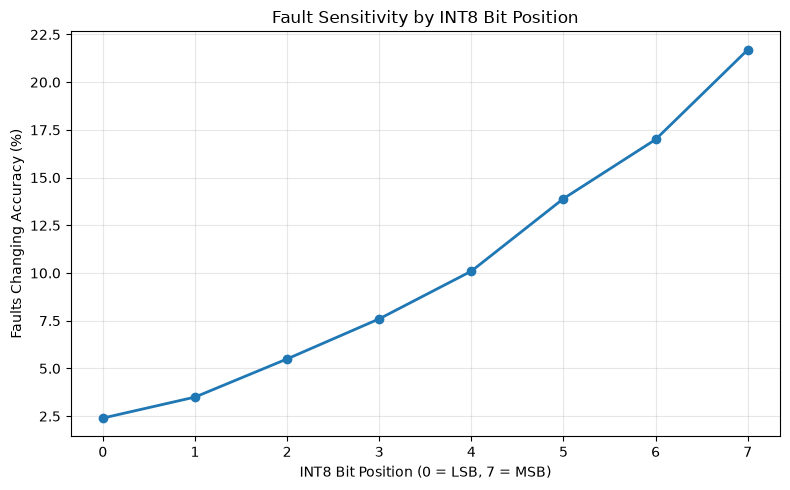

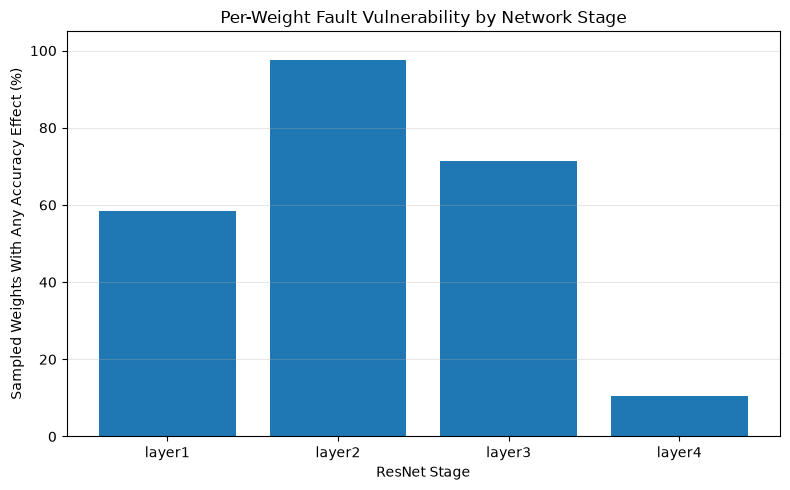

Saved:
figure_bit_position_sensitivity.png
figure_stage_vulnerability.png


In [49]:
# ============================================================
# FINAL REPORT FIGURES
# Figure 1: Fault sensitivity by bit position
# Figure 2: Per-weight vulnerability by ResNet stage
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# FIGURE 1 — BIT POSITION
# ------------------------------------------------------------

bit_plot = summary.sort_values("bit_position")

plt.figure(figsize=(8, 5))

plt.plot(
    bit_plot["bit_position"],
    bit_plot["changed_percent"],
    marker="o",
    linewidth=2
)

plt.xlabel("INT8 Bit Position (0 = LSB, 7 = MSB)")
plt.ylabel("Faults Changing Accuracy (%)")
plt.title("Fault Sensitivity by INT8 Bit Position")

plt.xticks(range(8))
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "figure_bit_position_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# FIGURE 2 — NETWORK STAGE
# ------------------------------------------------------------

stage_order = ["layer1", "layer2", "layer3", "layer4"]

stage_plot = (
    stage_weight_summary
    .set_index("stage")
    .loc[stage_order]
    .reset_index()
)

plt.figure(figsize=(8, 5))

plt.bar(
    stage_plot["stage"],
    stage_plot["any_effect_percent"]
)

plt.xlabel("ResNet Stage")
plt.ylabel("Sampled Weights With Any Accuracy Effect (%)")
plt.title("Per-Weight Fault Vulnerability by Network Stage")

plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "figure_stage_vulnerability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print("figure_bit_position_sensitivity.png")
print("figure_stage_vulnerability.png")

# Discussion

The experiments show that the effect of a single-bit fault depends strongly on both the **bit position** and the **location of the affected weight within the network**.

Higher-order INT8 bits are generally more influential than lower-order bits. Bit 7 changes the measured accuracy in **21.7%** of injections, while Bit 0 changes it in only **2.4%**. The mean accuracy degradation also decreases progressively toward the lower-order bits.

The paired statistical analysis confirms that bit position has a significant effect on fault impact. The Friedman test gives $p = 9.34 \times 10^{-138}$, while the post-hoc Wilcoxon analysis shows significant differences for 26 of the 28 bit-position pairs.

However, the effect is not determined by bit position alone. Vulnerability also varies substantially across the ResNet stages. Layer 2 is the most sensitive stage in the per-weight analysis, with **97.67%** of its sampled weights affected by at least one bit position. In contrast, only **10.53%** of sampled Layer 4 weights show any measurable effect.

The stage-level Kruskal–Wallis test confirms a significant difference among network stages, with an effect size of $\epsilon^2 = 0.4851$. For the better-sampled stages, the results support the vulnerability ordering:

**Layer 2 > Layer 3 > Layer 4**

The per-weight analysis also shows that vulnerability is concentrated in a relatively small subset of physical weights. Of the 1,000 sampled weights, **733 (73.3%)** do not produce any measurable accuracy change for any of the eight bit positions, while only **13 (1.3%)** are vulnerable to all eight bit flips.

Overall, these results suggest that fault tolerance in quantized neural networks is highly non-uniform. A small subset of weights and network regions contributes disproportionately to the observed sensitivity.

# Limitations

Several limitations should be considered when interpreting the results.

First, fault impact is evaluated using a fixed subset of **2,500 CIFAR-10 test images** rather than the complete 10,000-image test set. Since the subset contains 2,500 images, the smallest possible measured accuracy change is **0.04 percentage points**. Therefore, an injection reported as producing no accuracy change may still alter individual logits or predictions without changing the total number of correct classifications.

Second, the 1,000 fault locations are sampled uniformly from the complete set of quantized weights. Because later ResNet stages contain many more parameters than earlier stages, the number of sampled physical weights differs substantially between stages. In particular, only **12 Layer 1 weights** are sampled, so conclusions involving Layer 1 are less reliable than those for the better-sampled stages.

Third, the results are obtained for a single trained ResNet-18 model, a single dataset, and one INT8 post-training quantization configuration. The observed vulnerability patterns may therefore differ for other architectures, datasets, quantization methods, or trained model instances.

Finally, the experiments consider isolated **single-bit faults in one weight at a time**. They do not model multiple simultaneous faults, transient activation faults, memory bursts, or faults affecting other model components.

These limitations mean that the results should be interpreted as a controlled reliability study of this specific quantized model configuration rather than as a universal characterization of INT8 neural networks.

# Conclusion

This project evaluated the reliability of an INT8-quantized ResNet-18 under controlled single-bit faults in stored network weights.

A total of **8,000 fault injections** were performed by applying all eight INT8 bit flips to the same fixed set of **1,000 physical weight locations**. The experiments show that fault sensitivity is highly non-uniform.

Higher-order bits generally have a larger effect on classification accuracy than lower-order bits, and the paired statistical analysis confirms significant differences across bit positions.

Fault sensitivity also depends strongly on network location. Among the better-sampled stages, Layer 2 is the most vulnerable, followed by Layer 3, while Layer 4 is substantially more robust.

At the level of individual weights, most sampled locations are robust to all tested bit flips, while a relatively small subset accounts for most of the observed sensitivity.

Overall, the results show that reliability analysis of quantized neural networks should consider both **bit significance** and **weight location** rather than treating all stored parameters as equally vulnerable.

These findings can support future work on selective protection strategies, where stronger fault-mitigation mechanisms are applied only to the most critical bits, weights, or network regions.